Number of arms: 10

Epsilon-Greedy Results
-----------------------------
Q-values: [ 0.14 -0.03 -0.72 -0.03 -0.04 -0.04 -0.69 -0.82 -0.42 -0.29]
Arm selection counts: [ 28 152   9 211  58  21   5   6   3   7]
Average reward: -0.055397982445428935


/tmp/ipykernel_809/2202432514.py:28: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action] += (reward - q_values[action]) / counts[action]


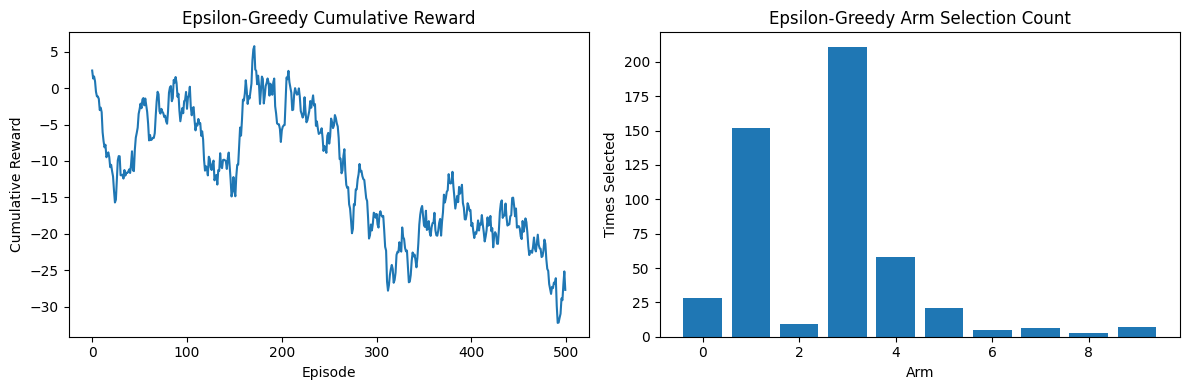


Softmax Results
-----------------------------
Q-values: [-0.01 -1.95  0.24 -0.03 -0.04 -0.38 -0.01 -0.77  0.4  -0.11]
Arm selection counts: [ 51   1  71  62  59   9  68  17 114  48]
Average reward: 0.06755129217581497


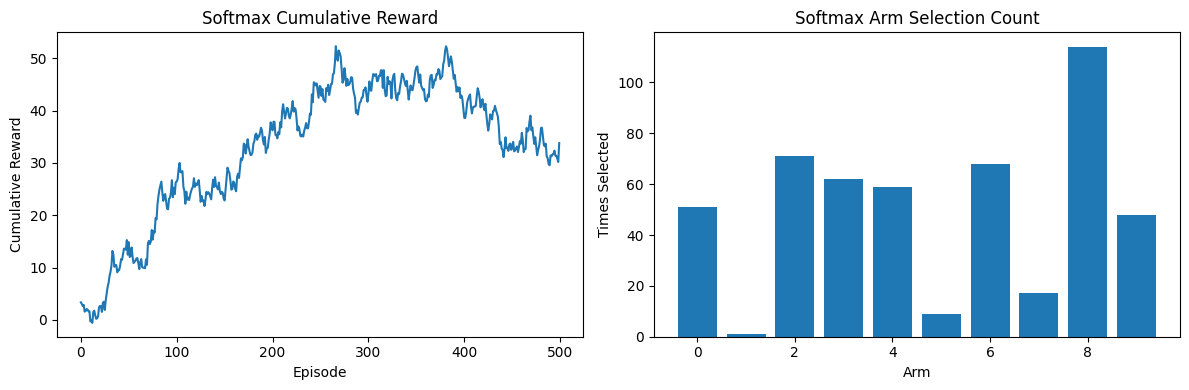

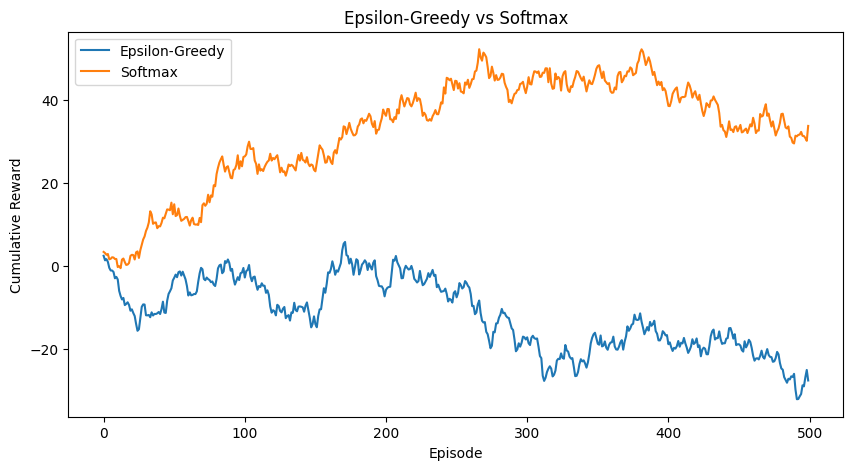

In [2]:
!pip install gym gym_bandits

import gym
import gym_bandits
import numpy as np
import matplotlib.pyplot as plt

np.bool8 = np.bool_
base_env = gym.make("MultiarmedBandits-v0")
env = base_env.unwrapped
n_arms = env.action_space.n
episodes = 500
print("Number of arms:", n_arms)
epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
rewards = []

for episode in range(episodes):
    env.reset()
    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:

        action = np.argmax(q_values)
    observation, reward, done, info = env.step(action)
    counts[action] += 1
    q_values[action] += (reward - q_values[action]) / counts[action]
    rewards.append(reward)

print("\nEpsilon-Greedy Results")
print("-----------------------------")
print("Q-values:", np.round(q_values, 2))
print("Arm selection counts:", counts.astype(int))
print("Average reward:", np.mean(rewards))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards))
plt.title("Epsilon-Greedy Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts)
plt.title("Epsilon-Greedy Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()

temperature = 0.5
q_values_softmax = np.zeros(n_arms)
counts_softmax = np.zeros(n_arms)
rewards_softmax = []
for episode in range(episodes):

    env.reset()
    probabilities = np.exp(q_values_softmax / temperature)
    probabilities = probabilities / np.sum(probabilities)
    action = np.random.choice(n_arms, p=probabilities)
    observation, reward, done, info = env.step(action)
    counts_softmax[action] += 1
    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]
    rewards_softmax.append(reward)

print("\nSoftmax Results")
print("-----------------------------")
print("Q-values:", np.round(q_values_softmax, 2))
print("Arm selection counts:", counts_softmax.astype(int))
print("Average reward:", np.mean(rewards_softmax))


plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)
plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)

plt.title("Epsilon-Greedy vs Softmax")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.legend()
plt.show()
env.close()

========== UCB ==========
Video Lectures selected 257 times
Interactive Quizzes selected 68 times
Gamified Modules selected 675 times
Total Reward = 664

========== Thompson Sampling ==========
Video Lectures selected 279 times
Interactive Quizzes selected 15 times
Gamified Modules selected 706 times
Total Reward = 671


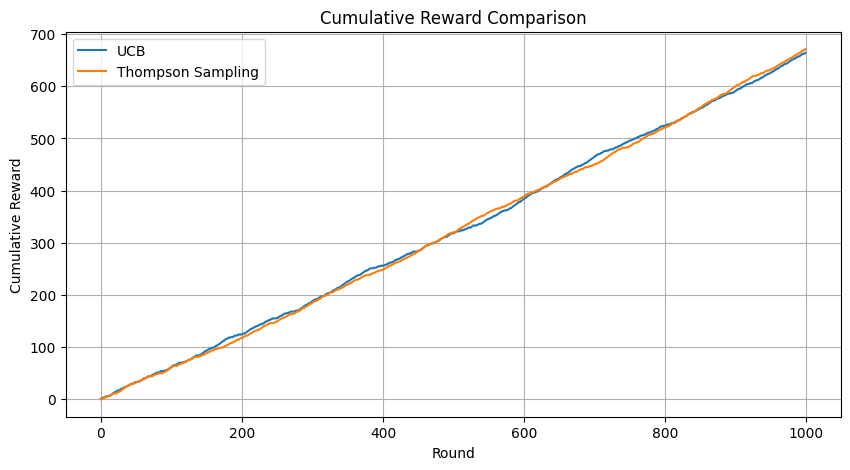

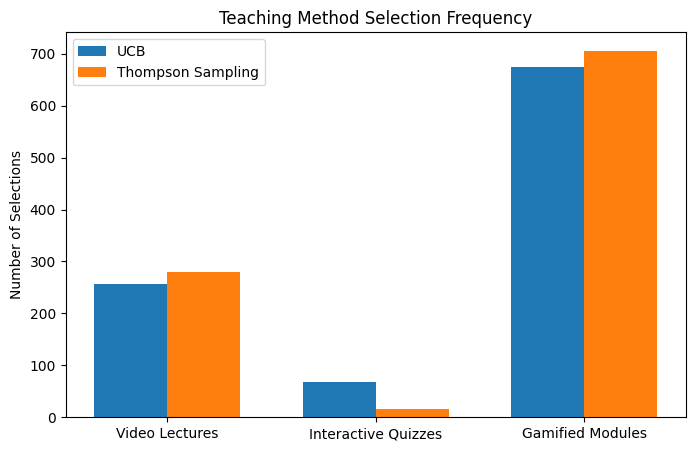

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
arms = ["Video Lectures", "Interactive Quizzes", "Gamified Modules"]
probabilities = [0.6, 0.4, 0.7]
n_arms = len(arms)
rounds = 1000
counts_ucb = np.zeros(n_arms)
values_ucb = np.zeros(n_arms)
rewards_ucb = []
cumulative_rewards_ucb = []
total_reward = 0
for t in range(rounds):

    if t < n_arms:
        action = t
    else:

        confidence = np.sqrt(
            (2 * np.log(t + 1)) / counts_ucb
        )

        ucb = values_ucb + confidence
        action = np.argmax(ucb)
    reward = np.random.binomial(1, probabilities[action])
    counts_ucb[action] += 1
    values_ucb[action] += (
        reward - values_ucb[action]
    ) / counts_ucb[action]
    total_reward += reward
    rewards_ucb.append(reward)
    cumulative_rewards_ucb.append(total_reward)

print("========== UCB ==========")
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ucb[i]), "times")

print("Total Reward =", total_reward)
alpha = np.ones(n_arms)
beta = np.ones(n_arms)
counts_ts = np.zeros(n_arms)
rewards_ts = []
cumulative_rewards_ts = []
total_reward = 0
for t in range(rounds):
    samples = np.random.beta(alpha, beta)
    action = np.argmax(samples)
    reward = np.random.binomial(1, probabilities[action])
    counts_ts[action] += 1

    if reward == 1:

        alpha[action] += 1
    else:

        beta[action] += 1
    total_reward += reward
    rewards_ts.append(reward)
    cumulative_rewards_ts.append(total_reward)

print("\n========== Thompson Sampling ==========")

for i in range(n_arms):
    print(arms[i], "selected", int(counts_ts[i]), "times")

print("Total Reward =", total_reward)
plt.figure(figsize=(10,5))

plt.plot(cumulative_rewards_ucb, label="UCB")
plt.plot(cumulative_rewards_ts, label="Thompson Sampling")
plt.xlabel("Round")
plt.ylabel("Cumulative Reward")
plt.title("Cumulative Reward Comparison")
plt.legend()
plt.grid()
plt.show()
x = np.arange(n_arms)
width = 0.35
plt.figure(figsize=(8,5))
plt.bar(x-width/2,
        counts_ucb,
        width,
        label="UCB")

plt.bar(x+width/2,
        counts_ts,
        width,
        label="Thompson Sampling")

plt.xticks(x, arms)
plt.ylabel("Number of Selections")
plt.title("Teaching Method Selection Frequency")
plt.legend()
plt.show()